<a href="https://colab.research.google.com/github/adeulofeut/Aplicaciones1/blob/main/Nacimientos_Colombia_DANE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Nacimientos en Colombia por departamento, 2020–2025

**Aplicaciones I**

## Integrantes del grupo

1. Juan Camilo Narváez Sánchez
2. Ronald Andres Garcia Diaz
3. Adrián Felipe Deulofeut Gil

## Objetivo

Estimar el número anual de nacidos vivos en los 32 departamentos de Colombia., según la residencia habitual de la madre. La unidad de
análisis es el conteo de nacimientos de un territorio durante un año calendario.

Primero, se usan los datos de 2020 a 2023 para estimar los nacimientos de 2024
y comparar las predicciones con las cifras observadas. Después, se selecciona
el método con mejor desempeño, se incorporan los datos de 2024 y se proyecta
2025. Las cifras definitivas de 2025 se reservan para evaluar la proyección
una vez generada.

## Fuente y cobertura

Se utilizan los cuadros agregados de nacimientos de las Estadísticas Vitales
del DANE, con cifras definitivas de enero a diciembre para cada año de 2020
a 2025. El gráfico 1 del boletín técnico del 24 de septiembre de 2026 sirve
para conciliar los totales nacionales. Los registros tardíos que el DANE
publica por separado quedan fuera del análisis.

[Estadísticas Vitales del DANE](https://www.dane.gov.co/index.php/estadisticas-por-tema/demografia-y-poblacion/nacimientos-y-defunciones) ·
[Boletín técnico del DANE](https://www.dane.gov.co/files/operaciones/EEVV/2026/24-sep-2026/bol-EEVV-Isem2026pr.pdf)

## Herramientas

- **pandas** lee los anexos y organiza los datos por territorio y año.
- **NumPy** realiza los cálculos y el redondeo de las proyecciones.
- **scikit-learn** entrena y evalúa los modelos de regresión.
- **Matplotlib** genera los ocho gráficos del cuaderno.

In [ ]:
import importlib.util
import subprocess
import sys

# Colab trae las bibliotecas principales. Instalar los lectores si faltan.
lectores = [paquete for modulo, paquete in [("xlrd", "xlrd"), ("openpyxl", "openpyxl"),
            ("msoffcrypto", "msoffcrypto-tool")] if importlib.util.find_spec(modulo) is None]
if lectores:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *lectores])

from io import BytesIO
from pathlib import Path
from urllib.parse import urlsplit
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import msoffcrypto
from IPython.display import HTML, Markdown, display
from matplotlib.ticker import FuncFormatter
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

def entero(valor):
    return f"{valor:,.0f}".replace(",", ".")

def decimal(valor, digitos=1):
    return f"{valor:,.{digitos}f}".translate(str.maketrans(",.", ".,"))

def mostrar(tabla, formatos=None):
    # HTML estático para que se vean todas las filas en Colab y en la exportación.
    display(HTML(tabla.to_html(index=False, formatters=formatos, na_rep="—")))

## 1. Inventario y descarga de los anexos

Se eligió la publicación **definitiva de enero a diciembre** para cada año. El DANE también publicó un corte preliminar de enero a julio de 2025 y un acumulado preliminar de enero a diciembre. Se emplea el definitivo de los doce meses. Si la descarga automática falla, abre el enlace directo o la publicación anual y descarga el anexo definitivo indicado en la tabla. En Colab, abre **Archivos** (icono de carpeta), pulsa **Subir al almacenamiento de la sesión**, carga el anexo con su nombre original en `/content` y repite la celda que falló. Los archivos cargados se eliminan al terminar la sesión, por lo que puede ser necesario volver a subirlos.

Los cuatro archivos XLS antiguos se abren en memoria con la clave estándar de compatibilidad de Excel para libros públicos protegidos contra escritura. Los XLSX se leen directamente.

En cada anexo se trabaja con **Cuadro 3**, una tabla agregada de nacimientos por área y sexo según departamento y municipio de residencia de la madre. Se toma la columna **Total** de las filas de subtotal departamental. Así, cada nacimiento ya está contado una vez dentro del subtotal publicado y no se vuelven a agregar las filas municipales ni las columnas desagregadas por sexo o área.

In [ ]:
BASE = "https://www.dane.gov.co"
PAGINA = BASE + "/index.php/estadisticas-por-tema/salud/nacimientos-y-defunciones/nacimientos/nacimientos-"
ANEXOS = [
    "investigaciones/poblacion/2022/14-febrero-2022/nacimientos2020-cuadro-definitivo-2020.xls",
    "investigaciones/poblacion/2022/22-diciembre-2022/nacimientos2021-cuadro-definitivo-2021.xls",
    "operaciones/EEVV/2023/21-diciembre-2023/nacimientos2022-cuadro-definitivo-2022.xls",
    "operaciones/EEVV/2024/19-dic-2024/anex-EEVV-Nacimientos2023pCuadroDefinivo-2023.xls",
    "operaciones/EEVV/2026/6-feb-2026/anex-EEVV-NacimientosCuadroAcumulado-2024.xlsx",
    "operaciones/EEVV/2026/24-sep-2026/anex-EEVV-NacimientosCuadroAcumulado-2025.xlsx"
    ]
FECHAS = ["14/02/2022", "22/12/2022", "21/12/2023", "19/12/2024",
          "25/09/2025 (actualizado 06/02/2026)", "24/09/2026"]
TOTAL_BOLETIN = dict(zip(range(2020, 2026), [629402, 616914, 573625, 515549, 453901, 441537]))

fuentes = {}
lineas = ["| Año | Publicación anual | Archivo oficial | Cobertura | Estado | Fecha |",
          "|---|---|---|---|---|---|"]
for anio, ruta, fecha in zip(range(2020, 2026), ANEXOS, FECHAS):
    url = BASE + "/files/" + ruta
    nombre = Path(urlsplit(url).path).name
    fuentes[anio] = (url, nombre)
    lineas.append(f"| {anio} | [DANE {anio}]({PAGINA}{anio}) | [{nombre}]({url}) | Enero a diciembre | Definitivo | {fecha} |")
display(Markdown(chr(10).join(lineas)))

def descargar(anio):
    url, nombre = fuentes[anio]
    archivo = Path(nombre)
    if archivo.exists():
        return archivo

    carpeta = Path("datos_dane")
    carpeta.mkdir(exist_ok=True)
    archivo = carpeta / nombre
    if archivo.exists():
        return archivo

    try:
        with urlopen(Request(url, headers={"User-Agent": "Mozilla/5.0"}), timeout=120) as respuesta:
            contenido = respuesta.read()
        firma = bytes.fromhex("D0CF11E0A1B11AE1") if archivo.suffix == ".xls" else b"PK"
        if not contenido.startswith(firma):
            raise ValueError("La respuesta no parece un archivo de Excel.")
    except (OSError, ValueError) as error:
        raise RuntimeError(f"Descarga {nombre} desde {url}, súbelo a /content y repite la celda.") from error

    temporal = archivo.with_suffix(".descarga")
    temporal.write_bytes(contenido)
    temporal.replace(archivo)
    return archivo

| Año | Publicación anual | Archivo oficial | Cobertura | Estado | Fecha |
|---|---|---|---|---|---|
| 2020 | [DANE 2020](https://www.dane.gov.co/index.php/estadisticas-por-tema/salud/nacimientos-y-defunciones/nacimientos/nacimientos-2020) | [nacimientos2020-cuadro-definitivo-2020.xls](https://www.dane.gov.co/files/investigaciones/poblacion/2022/14-febrero-2022/nacimientos2020-cuadro-definitivo-2020.xls) | Enero a diciembre | Definitivo | 14/02/2022 |
| 2021 | [DANE 2021](https://www.dane.gov.co/index.php/estadisticas-por-tema/salud/nacimientos-y-defunciones/nacimientos/nacimientos-2021) | [nacimientos2021-cuadro-definitivo-2021.xls](https://www.dane.gov.co/files/investigaciones/poblacion/2022/22-diciembre-2022/nacimientos2021-cuadro-definitivo-2021.xls) | Enero a diciembre | Definitivo | 22/12/2022 |
| 2022 | [DANE 2022](https://www.dane.gov.co/index.php/estadisticas-por-tema/salud/nacimientos-y-defunciones/nacimientos/nacimientos-2022) | [nacimientos2022-cuadro-definitivo-2022.xls](https://www.dane.gov.co/files/operaciones/EEVV/2023/21-diciembre-2023/nacimientos2022-cuadro-definitivo-2022.xls) | Enero a diciembre | Definitivo | 21/12/2023 |
| 2023 | [DANE 2023](https://www.dane.gov.co/index.php/estadisticas-por-tema/salud/nacimientos-y-defunciones/nacimientos/nacimientos-2023) | [anex-EEVV-Nacimientos2023pCuadroDefinivo-2023.xls](https://www.dane.gov.co/files/operaciones/EEVV/2024/19-dic-2024/anex-EEVV-Nacimientos2023pCuadroDefinivo-2023.xls) | Enero a diciembre | Definitivo | 19/12/2024 |
| 2024 | [DANE 2024](https://www.dane.gov.co/index.php/estadisticas-por-tema/salud/nacimientos-y-defunciones/nacimientos/nacimientos-2024) | [anex-EEVV-NacimientosCuadroAcumulado-2024.xlsx](https://www.dane.gov.co/files/operaciones/EEVV/2026/6-feb-2026/anex-EEVV-NacimientosCuadroAcumulado-2024.xlsx) | Enero a diciembre | Definitivo | 25/09/2025 (actualizado 06/02/2026) |
| 2025 | [DANE 2025](https://www.dane.gov.co/index.php/estadisticas-por-tema/salud/nacimientos-y-defunciones/nacimientos/nacimientos-2025) | [anex-EEVV-NacimientosCuadroAcumulado-2025.xlsx](https://www.dane.gov.co/files/operaciones/EEVV/2026/24-sep-2026/anex-EEVV-NacimientosCuadroAcumulado-2025.xlsx) | Enero a diciembre | Definitivo | 24/09/2026 |

## 2. Construcción y control del panel

Usamos los códigos DIVIPOLA de dos dígitos y nombres uniformes. Bogotá D. C. (11) se trata como territorio propio, separado de Cundinamarca (25). La suma territorial incluye los 32 departamentos y Bogotá. La residencia en el exterior y los casos sin departamento identificado se contabilizan en la conciliación y se excluyen del panel. Tampoco se redistribuyen entre departamentos.

El código verifica que el Cuadro 3 corresponda al año y a residencia de la madre, que estén los 33 territorios una sola vez y que los conteos sean enteros, no negativos y completos. Se compara el total del cuadro con el boletín del DANE. Si hay una diferencia sin explicar o un territorio faltante, se detiene la ejecución para revisar el anexo. En cuadros agregados se pueden auditar claves duplicadas, pero no certificados individuales.

In [ ]:
DIVIPOLA = {
    "05": "Antioquia", "08": "Atlántico", "11": "Bogotá D. C.", "13": "Bolívar",
    "15": "Boyacá", "17": "Caldas", "18": "Caquetá", "19": "Cauca",
    "20": "Cesar", "23": "Córdoba", "25": "Cundinamarca", "27": "Chocó",
    "41": "Huila", "44": "La Guajira", "47": "Magdalena", "50": "Meta",
    "52": "Nariño", "54": "Norte de Santander", "63": "Quindío",
    "66": "Risaralda", "68": "Santander", "70": "Sucre", "73": "Tolima",
    "76": "Valle del Cauca", "81": "Arauca", "85": "Casanare",
    "86": "Putumayo", "88": "San Andrés, Providencia y Santa Catalina",
    "91": "Amazonas", "94": "Guainía", "95": "Guaviare", "97": "Vaupés", "99": "Vichada",
}

def leer_anio(anio):
    archivo = descargar(anio)
    origen = archivo
    if archivo.suffix.lower() == ".xls":
        with archivo.open("rb") as flujo:
            libro_excel = msoffcrypto.OfficeFile(flujo)
            if libro_excel.is_encrypted():
                libro_excel.load_key(password="VelvetSweatshop")
                origen = BytesIO()
                libro_excel.decrypt(origen)
                origen.seek(0)
    with pd.ExcelFile(origen) as libro:
        hoja = next(nombre for nombre in libro.sheet_names
                    if nombre.lower().replace(" ", "") == "cuadro3")
        bruto = libro.parse(hoja, header=None, usecols="A:E", dtype=object)

    encabezado = " ".join(bruto.head(9).fillna("").astype(str).to_numpy().ravel()).lower()
    if "residencia de la madre" not in encabezado or str(anio) not in encabezado:
        raise ValueError(f"{anio}: encabezado inesperado en {hoja}.")

    cuadro = bruto.set_axis(["codigo", "municipio", "rotulo", "detalle", "total"], axis=1)
    cuadro["codigo"] = cuadro["codigo"].astype(str).str.replace(r"[.]0$", "", regex=True).str.strip().str.zfill(2)
    cuadro["rotulo"] = cuadro["rotulo"].fillna("").astype(str).str.strip()
    nacionales = cuadro.loc[cuadro["rotulo"].str.fullmatch("Total Nacional", case=False), "total"]
    if len(nacionales) != 1 or nacionales.iloc[0] != TOTAL_BOLETIN[anio]:
        raise ValueError(f"{anio}: total del Cuadro 3 distinto del total oficial.")

    # La columna de rótulo identifica el encabezado de cada departamento.
    territorios = cuadro.loc[cuadro["codigo"].isin(DIVIPOLA) & cuadro["detalle"].fillna("").str.fullmatch("Total(?: Dpto)?", case=False),
                             ["codigo", "total"]].copy()
    if territorios["codigo"].duplicated().any() or set(territorios["codigo"]) != set(DIVIPOLA):
        raise ValueError(f"{anio}: faltan territorios o hay subtotales duplicados.")
    conteos = pd.to_numeric(territorios["total"], errors="raise")
    if conteos.isna().any() or (conteos < 0).any() or (conteos % 1 != 0).any():
        raise ValueError(f"{anio}: conteos departamentales inválidos.")
    territorios["nacimientos"] = conteos.astype(int)
    territorios["departamento"] = territorios["codigo"].map(DIVIPOLA)
    territorios["anio"] = anio

    nacional = int(nacionales.iloc[0])
    territorial = int(conteos.sum())
    excluidos = leer_excluidos(cuadro)
    if nacional - territorial != sum(excluidos.values()):
        raise ValueError(f"{anio}: diferencia sin conciliar entre el total oficial y el panel.")
    control = {"Año": anio, "Total boletín DANE": TOTAL_BOLETIN[anio],
               "Total Cuadro 3": nacional, "Suma territorial": territorial,
               **excluidos, "Diferencia": nacional - territorial}
    return territorios[["codigo", "departamento", "anio", "nacimientos"]], control

def leer_excluidos(cuadro):
    # Las etiquetas de las categorías se verifican con los seis anexos.
    texto = cuadro["rotulo"].str.lower()
    categorias = {"Exterior": r"exterior|extranjero",
                  "Sin departamento identificado": r"sin informaci[oó]n|sin identificar|desconocid"}
    resultados = {}
    for categoria, patron in categorias.items():
        valores = cuadro.loc[texto.str.contains(patron, regex=True), "total"]
        if len(valores) != 1 or pd.isna(valores.iloc[0]):
            raise ValueError(f"Subtotal faltante o repetido para {categoria}.")
        resultados[categoria] = int(valores.iloc[0])
    return resultados

historico = [leer_anio(anio) for anio in range(2020, 2025)]
panel = pd.concat([datos for datos, control in historico], ignore_index=True)
assert len(panel) == 5 * len(DIVIPOLA)
assert not panel.duplicated(["codigo", "anio"]).any()
assert not panel.isna().any().any()
auditoria = pd.DataFrame([control for datos, control in historico])
mostrar(auditoria, {col: entero for col in auditoria.columns if col != "Año"})

Año,Total boletín DANE,Total Cuadro 3,Suma territorial,Exterior,Sin departamento identificado,Diferencia
2020,629.402,629.402,619.602,9.789,11,9.800
2021,616.914,616.914,608.083,8.828,3,8.831
2022,573.625,573.625,567.227,4.313,2.085,6.398
2023,515.549,515.549,508.299,3.162,4.088,7.250
2024,453.901,453.901,443.148,2.448,8.305,10.753


## 3. Exploración y variables

El cambio interanual se calcula como `100 × (total actual / total anterior − 1)` sobre los mismos 33 territorios. La exploración territorial muestra el volumen en 2024 y el cambio respecto de 2023. Son conteos: las diferencias también reflejan el tamaño de la población y por sí solas no miden fecundidad.

La variable dependiente es **nacimientos anuales por territorio**. El departamento identifica diferencias persistentes de escala y se codifica como categoría. El año permite que el modelo lineal estime una tendencia temporal. El rezago de un año resume la escala reciente y se incorpora uniendo cada territorio con sus propios datos de exactamente un año antes. Como no usamos 2019, 2020 aporta el rezago para 2021 y no entra como fila objetivo de entrenamiento.

El corte temporal sigue los años de ocurrencia. Las cifras definitivas del año anterior pueden publicarse durante el año estimado o después, por lo que esta es una simulación retrospectiva con datos consolidados. Para replicar un pronóstico a fecha fija habría que reconstruir las versiones publicadas hasta esa fecha.

In [ ]:
serie = panel.groupby("anio")["nacimientos"].sum().sort_index()
variacion = serie.pct_change().mul(100)
tabla_serie = pd.DataFrame({"Año": serie.index, "Nacimientos": serie.values,
                            "Variación anual (%)": variacion.values})
mostrar(tabla_serie, {"Nacimientos": entero, "Variación anual (%)": decimal})

comparacion = panel.pivot(index="departamento", columns="anio", values="nacimientos")
territorial_2024 = comparacion[[2023, 2024]].copy()
territorial_2024["Variación anual (%)"] = territorial_2024[2024].div(territorial_2024[2023]).sub(1).mul(100)
territorial_2024 = territorial_2024.sort_values(2024, ascending=False).reset_index()
mostrar(territorial_2024, {2023: entero, 2024: entero, "Variación anual (%)": decimal})
mayor, menor = territorial_2024.iloc[0], territorial_2024.iloc[-1]
cambio = (serie.loc[2024] / serie.loc[2020] - 1) * 100
mayor_caida = variacion.idxmin()
display(Markdown(
    f"Entre 2020 y 2024 el cambio acumulado fue **{decimal(cambio)} %**. "
    f"La mayor caída interanual del período ocurrió en **{mayor_caida}** "
    f"(**{decimal(variacion.loc[mayor_caida])} %**). En 2024, "
    f"**{mayor['departamento']}** registró {entero(mayor[2024])} nacimientos y "
    f"**{menor['departamento']}**, {entero(menor[2024])}."
))

rezagos = panel[["codigo", "anio", "nacimientos"]].rename(columns={"nacimientos": "rezago"})
rezagos = rezagos.assign(anio=rezagos["anio"] + 1)
con_rezago = panel.merge(rezagos, on=["codigo", "anio"], how="left", validate="one_to_one")
assert con_rezago["rezago"].isna().eq(con_rezago["anio"].eq(2020)).all()

Año,Nacimientos,Variación anual (%)
2020,619.602,—
2021,608.083,"-1,9"
2022,567.227,"-6,7"
2023,508.299,"-10,4"
2024,443.148,"-12,8"


anio,departamento,2023,2024,Variación anual (%)
,Bogotá D. C.,60.912,56.541,"-7,2"
,Antioquia,59.017,52.171,"-11,6"
,Valle del Cauca,36.514,33.055,"-9,5"
,Cundinamarca,29.061,27.060,"-6,9"
,Atlántico,31.727,26.237,"-17,3"
,Bolívar,29.953,24.559,"-18,0"
,Santander,21.890,18.659,"-14,8"
,Córdoba,21.080,17.625,"-16,4"
,La Guajira,20.333,17.339,"-14,7"
,Magdalena,19.865,15.857,"-20,2"


Entre 2020 y 2024 el cambio acumulado fue **-28,5 %**. La mayor caída interanual del período ocurrió en **2024** (**-12,8 %**). En 2024, **Bogotá D. C.** registró 56.541 nacimientos y **Vaupés**, 545.

### Tendencias nacionales y territoriales

Las barras nacionales muestran el cambio frente al año anterior en los 33 territorios. Las líneas departamentales usan 2020 como base 100 y muestran los seis territorios con más nacimientos en ese año. Un índice de 80 equivale a 20 % menos nacimientos que en 2020. El mapa de calor incluye todos los territorios y permite ver cuándo se concentraron las caídas y qué departamentos se apartaron del patrón.

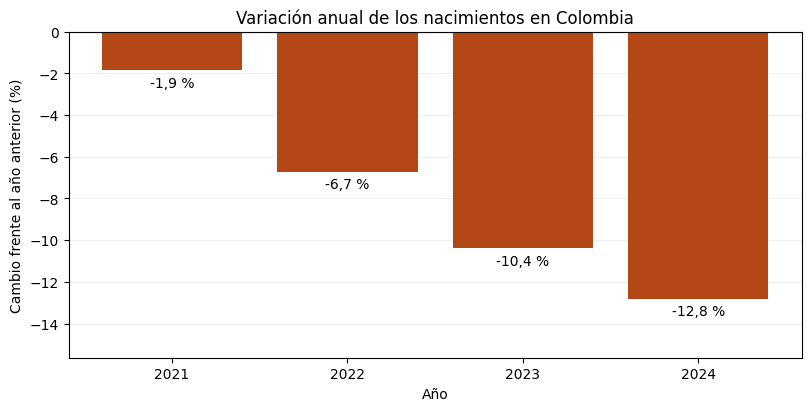

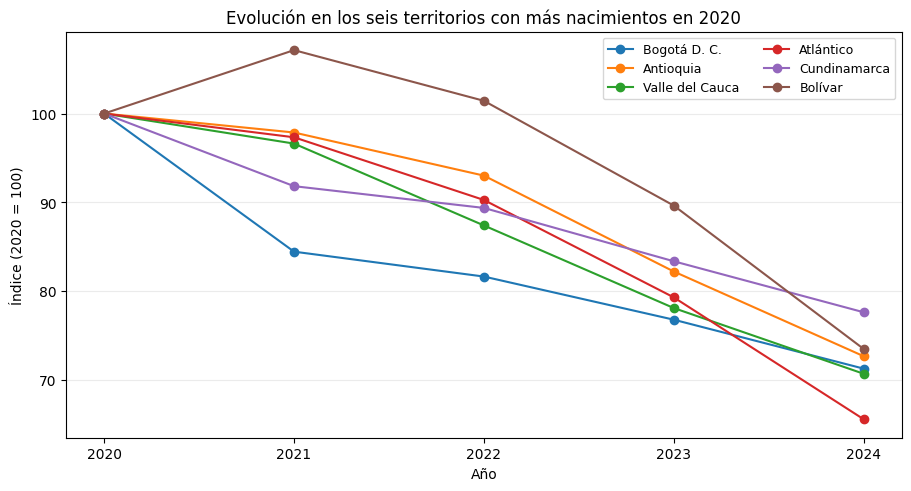

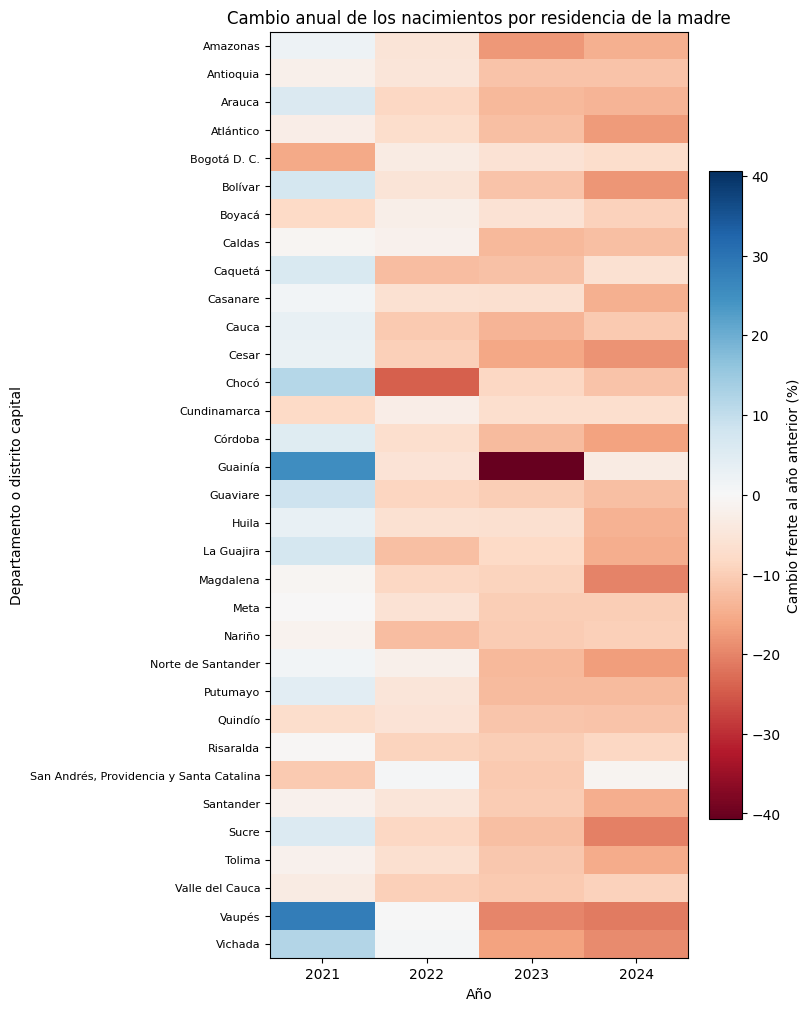

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
cambios = variacion.dropna()
barras = ax.bar(cambios.index, cambios, color=np.where(cambios < 0, "#b34716", "#006478"))
ax.bar_label(barras, labels=[f"{decimal(v)} %" for v in cambios], padding=4)
ax.axhline(0, color="#555555", linewidth=0.8)
ax.set(title="Variación anual de los nacimientos en Colombia",
       xlabel="Año", ylabel="Cambio frente al año anterior (%)", xticks=cambios.index)
ax.margins(y=0.22)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.8), layout="constrained")
principales = comparacion[2020].nlargest(6).index
for territorio in principales:
    serie_territorial = comparacion.loc[territorio]
    indice = 100 * serie_territorial / serie_territorial.loc[2020]
    ax.plot(indice.index, indice, marker="o", label=territorio)
ax.set(title="Evolución en los seis territorios con más nacimientos en 2020",
       xlabel="Año", ylabel="Índice (2020 = 100)", xticks=comparacion.columns)
ax.grid(axis="y", alpha=0.25)
ax.legend(ncol=2, fontsize=9)
plt.show()

cambios_territoriales = comparacion.sort_index().pct_change(axis=1).iloc[:, 1:] * 100
escala = np.abs(cambios_territoriales.to_numpy()).max()
fig, ax = plt.subplots(figsize=(8, 10), layout="constrained")
mapa = ax.imshow(cambios_territoriales, aspect="auto", cmap="RdBu",
                 vmin=-escala, vmax=escala, interpolation="nearest")
ax.set(title="Cambio anual de los nacimientos por residencia de la madre",
       xlabel="Año", ylabel="Departamento o distrito capital",
       xticks=range(len(cambios_territoriales.columns)),
       xticklabels=cambios_territoriales.columns,
       yticks=range(len(cambios_territoriales)),
       yticklabels=cambios_territoriales.index)
ax.tick_params(axis="y", labelsize=8)
fig.colorbar(mapa, ax=ax, shrink=0.7, label="Cambio frente al año anterior (%)")
plt.show()

## 4. Prueba histórica de 2024 y selección

Se ajustan la **regresión lineal** y **Random Forest** con objetivos de 2021 a 2023 y rezagos de 2020 a 2022. Ambos ven las mismas variables y se evalúan sobre los mismos 33 territorios de 2024. La **persistencia** predice el conteo observado en 2023 y sirve de referencia. La codificación categórica se ajusta dentro de cada modelo sobre las filas de entrenamiento.

La regresión lineal puede extrapolar una tendencia anual común. Random Forest aprende relaciones no lineales, aunque sus árboles no extrapolan una tendencia más allá de los años de entrenamiento. Fijamos de antemano los parámetros del bosque y la semilla. Se selecciona el menor MAE de 2024 entre los tres métodos. Si hay empate, gana el menor RMSE y luego el nombre en orden alfabético.

El **MAE** mide el error absoluto medio en nacimientos por territorio. El **RMSE** también se expresa en nacimientos y penaliza más los errores grandes. **R²** mide el desempeño respecto de una predicción constante igual a la media observada del conjunto evaluado y puede ser negativo. Para evaluar y proyectar se fijan en cero las predicciones negativas. Las métricas de 2024 se calculan antes del redondeo.

In [ ]:
variables = ["codigo", "anio", "rezago"]
entrenamiento = con_rezago.loc[con_rezago["anio"].between(2021, 2023)]
prueba = con_rezago.loc[con_rezago["anio"].eq(2024)].sort_values("codigo")
assert len(entrenamiento) == 99 and len(prueba) == 33

def modelo(regresor):
    transformador = ColumnTransformer(
        [("departamento", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["codigo"])],
        remainder="passthrough",
    )
    return make_pipeline(transformador, regresor)

candidatos = {
    "Regresión lineal": modelo(LinearRegression()),
    "Random Forest": modelo(RandomForestRegressor(n_estimators=400, min_samples_leaf=2, random_state=42, n_jobs=-1)),
}
referencia = "Persistencia"
predicciones = {referencia: prueba["rezago"].to_numpy()}
for nombre, candidato in candidatos.items():
    ajustado = clone(candidato).fit(entrenamiento[variables], entrenamiento["nacimientos"])
    predicciones[nombre] = np.maximum(ajustado.predict(prueba[variables]), 0)

def evaluar(observado, estimado):
    return {"MAE": mean_absolute_error(observado, estimado),
            "RMSE": np.sqrt(mean_squared_error(observado, estimado)),
            "R²": r2_score(observado, estimado)}

metricas = pd.DataFrame([{"Método": nombre, **evaluar(prueba["nacimientos"], valores)}
                         for nombre, valores in predicciones.items()])
metricas = metricas.sort_values(["MAE", "RMSE", "Método"], ignore_index=True)
formatos_metricas = {"MAE": decimal, "RMSE": decimal, "R²": lambda valor: decimal(valor, 4)}
mostrar(metricas, formatos_metricas)
elegido = metricas.loc[0, "Método"]

detalle_2024 = prueba[["codigo", "departamento", "nacimientos"]].rename(
    columns={"codigo": "Código", "departamento": "Departamento", "nacimientos": "Observado"}
).assign(Estimado=predicciones[elegido])
detalle_2024["Error absoluto"] = detalle_2024["Estimado"].sub(detalle_2024["Observado"]).abs()
detalle_2024 = detalle_2024.sort_values("Error absoluto", ascending=False)
display(Markdown(f"**Prueba de 2024 por departamento · {elegido}**"))
mostrar(detalle_2024, {"Observado": entero, "Estimado": decimal, "Error absoluto": decimal})

Método,MAE,RMSE,R²
Random Forest,"1.373,1","2.378,4","0,9683"
Regresión lineal,"1.506,0","1.957,9","0,9785"
Persistencia,"1.974,3","2.666,7","0,9601"


**Prueba de 2024 por departamento · Random Forest**

Código,Departamento,Observado,Estimado,Error absoluto
05,Antioquia,52.171,"61.243,3","9.072,3"
13,Bolívar,24.559,"30.401,0","5.842,0"
08,Atlántico,26.237,"30.921,1","4.684,1"
11,Bogotá D. C.,56.541,"61.103,4","4.562,4"
20,Cesar,14.802,"17.348,8","2.546,8"
70,Sucre,9.537,"11.717,4","2.180,4"
47,Magdalena,15.857,"17.616,9","1.759,9"
54,Norte de Santander,15.765,"17.378,8","1.613,8"
44,La Guajira,17.339,"18.563,7","1.224,7"
41,Huila,12.983,"14.176,7","1.193,7"


## Resultado nacional de la prueba de 2024

El total nacional de la prueba se calcula sumando las predicciones de los 32 departamentos y Bogotá D. C. Se compara con el observado de 2024 para esos mismos territorios. La diferencia porcentual usa el observado de 2024 como denominador. Las dos variaciones anuales se calculan respecto del observado de 2023.



In [ ]:
observado_2023 = serie.loc[2023]
observado_2024 = detalle_2024["Observado"].sum()
estimado_2024 = detalle_2024["Estimado"].sum()
diferencia_2024 = estimado_2024 - observado_2024
error_pct_2024 = 100 * diferencia_2024 / observado_2024
cambio_observado_2024 = 100 * (observado_2024 / observado_2023 - 1)
cambio_estimado_2024 = 100 * (estimado_2024 / observado_2023 - 1)

resumen_2024 = pd.DataFrame([{
    "Modelo": elegido,
    "Observado": observado_2024,
    "Estimado": estimado_2024,
    "Diferencia (estimado − observado)": diferencia_2024,
    "Diferencia (%)": error_pct_2024,
}])
mostrar(resumen_2024, {
    "Observado": entero,
    "Estimado": decimal,
    "Diferencia (estimado − observado)": decimal,
    "Diferencia (%)": decimal,
})
display(Markdown(
    f"En 2024, el cambio observado frente a 2023 fue **{decimal(cambio_observado_2024)} %** "
    f"y el cambio estimado fue **{decimal(cambio_estimado_2024)} %**. "
    f"La diferencia nacional fue **{decimal(error_pct_2024)} %** del observado. "
    "El R² mide el desempeño entre territorios. La diferencia nacional muestra "
    "el saldo de los errores territoriales con signo."
))


Modelo,Observado,Estimado,Diferencia (estimado − observado),Diferencia (%)
Random Forest,443.148,"487.639,1","44.491,1","10,0"


En 2024, el cambio observado frente a 2023 fue **-12,8 %** y el cambio estimado fue **-4,1 %**. La diferencia nacional fue **10,0 %** del observado. El R² mide el desempeño entre territorios. La diferencia nacional muestra el saldo de los errores territoriales con signo.

### Desempeño de los métodos en 2024

Las barras comparan MAE y RMSE en unidades de nacimientos. En el gráfico de dispersión, cada punto representa un territorio. La diagonal indica coincidencia entre el valor estimado y el observado. Los puntos por debajo de la diagonal indican subestimación. Se identifican los tres territorios con mayor error absoluto del método elegido.

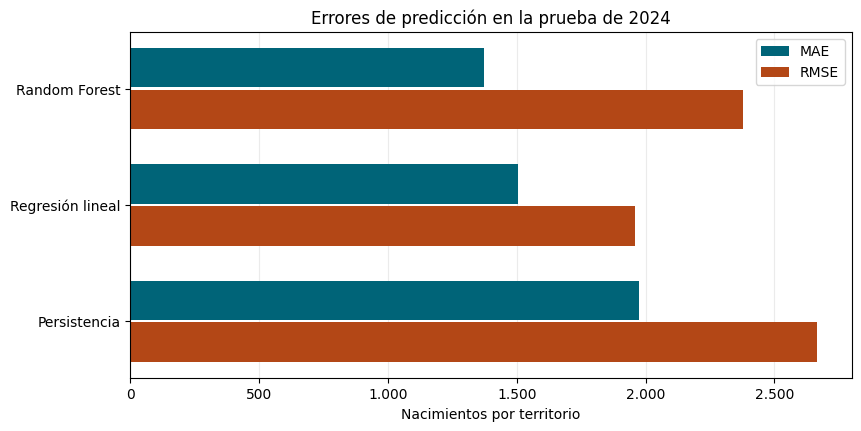

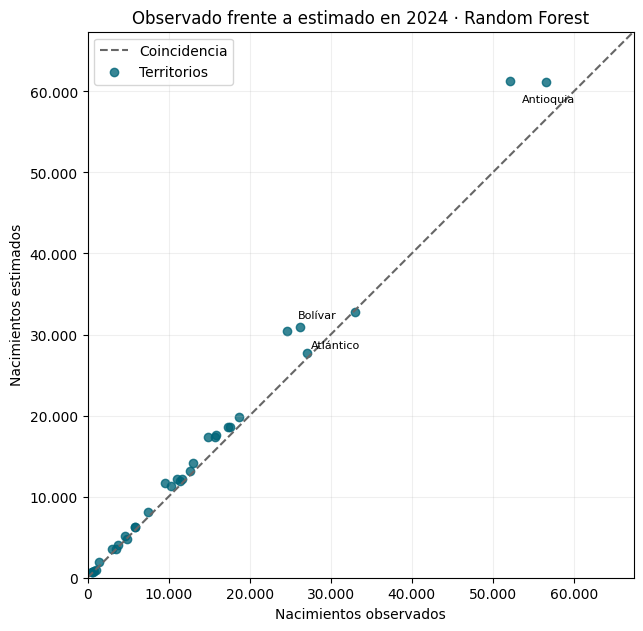

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 4.2), layout="constrained")
posiciones = np.arange(len(metricas))
ax.barh(posiciones - 0.18, metricas["MAE"], height=0.34, color="#006478", label="MAE")
ax.barh(posiciones + 0.18, metricas["RMSE"], height=0.34, color="#b34716", label="RMSE")
ax.set(title="Errores de predicción en la prueba de 2024",
       xlabel="Nacimientos por territorio", yticks=posiciones, yticklabels=metricas["Método"])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: entero(v)))
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 6.2), layout="constrained")
limite = 1.10 * detalle_2024[["Observado", "Estimado"]].max().max()
ax.plot([0, limite], [0, limite], linestyle="--", color="#666666", label="Coincidencia")
ax.scatter(detalle_2024["Observado"], detalle_2024["Estimado"],
           color="#006478", alpha=0.78, label="Territorios")
for fila, desplazamiento in zip(detalle_2024.head(3).to_dict("records"),
                                [(8, -15), (8, 9), (8, -15)]):
    ax.annotate(fila["Departamento"], (fila["Observado"], fila["Estimado"]),
                xytext=desplazamiento, textcoords="offset points", fontsize=8)
ax.set(title=f"Observado frente a estimado en 2024 · {elegido}",
       xlabel="Nacimientos observados", ylabel="Nacimientos estimados",
       xlim=(0, limite), ylim=(0, limite), aspect="equal")
for eje in (ax.xaxis, ax.yaxis):
    eje.set_major_formatter(FuncFormatter(lambda v, p: entero(v)))
ax.grid(alpha=0.2)
ax.legend()
plt.show()

## 5. Proyección de 2025

Si gana un modelo entrenable, se vuelve a ajustar con objetivos de 2021 a 2024. Si gana persistencia, la regla se actualiza con el observado de 2024. La proyección usa el código territorial, el año 2025 y el rezago de 2024. Los nacimientos observados de 2025 se leen después de generar la tabla y los gráficos.

Se redondea cada predicción no negativa al entero más cercano. Los valores exactamente a mitad se redondean hacia arriba. El total nacional estimado se calcula sumando esos 33 enteros y se usa en el gráfico nacional. La cobertura es idéntica para 2020–2025.

**Total nacional estimado de 2025 · 406.913 nacimientos**

Código,Departamento,Proyección 2025
11,Bogotá D. C.,55.623
05,Antioquia,46.769
76,Valle del Cauca,31.567
25,Cundinamarca,25.604
08,Atlántico,24.993
13,Bolívar,22.055
68,Santander,15.883
23,Córdoba,15.801
44,La Guajira,15.747
47,Magdalena,14.460


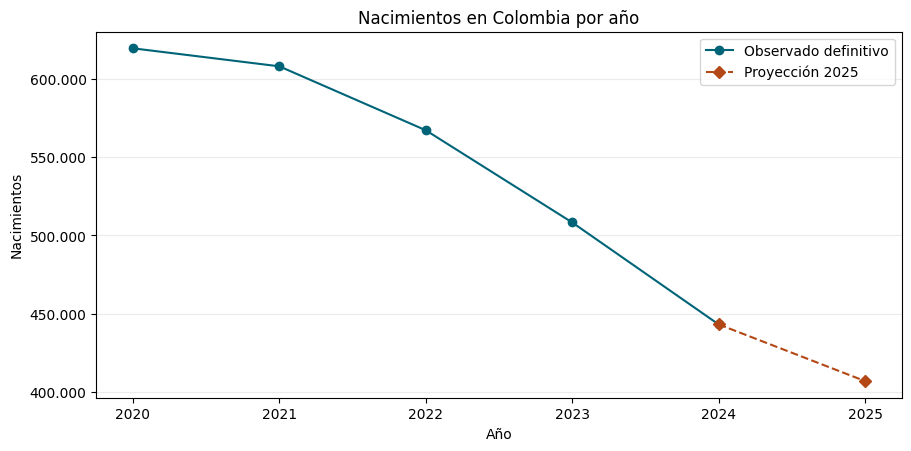

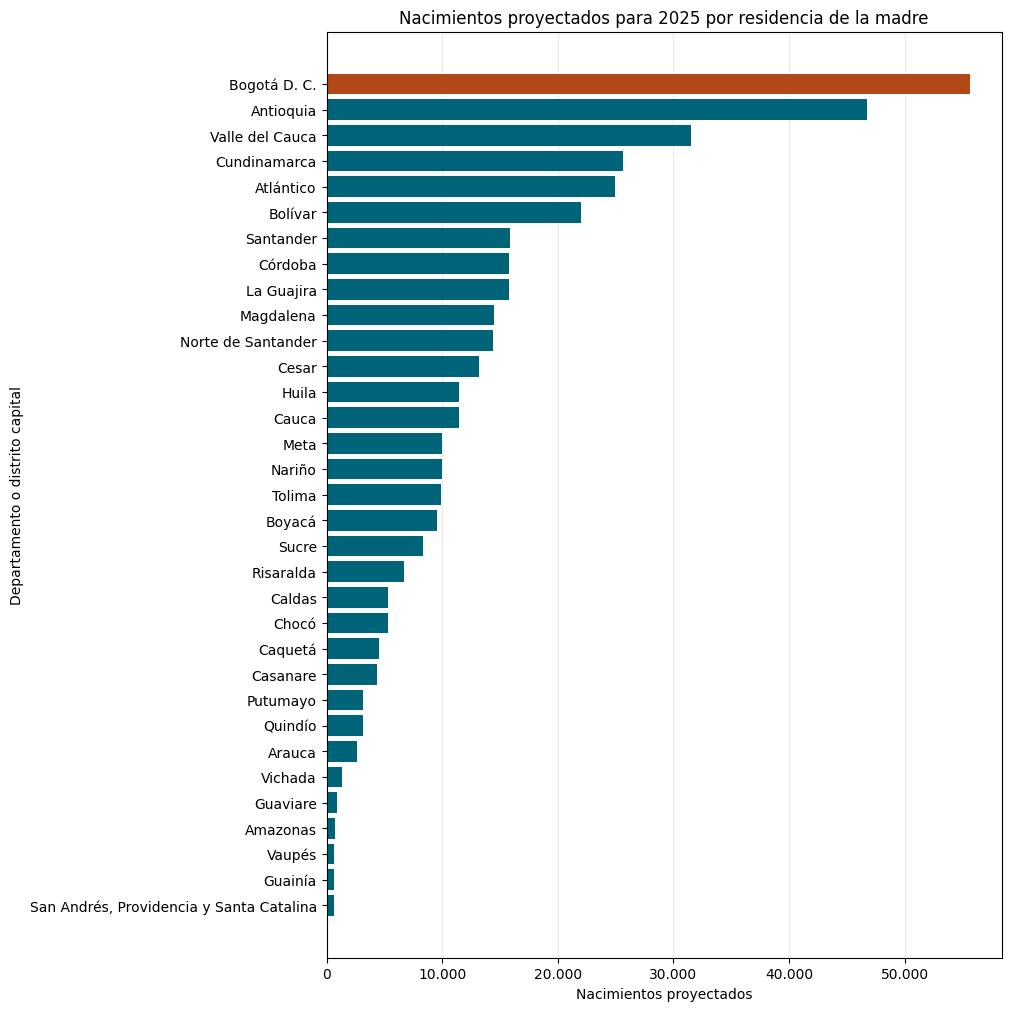

In [ ]:
ajuste_final = con_rezago.loc[con_rezago["anio"].between(2021, 2024)]
futuro = rezagos.loc[rezagos["anio"].eq(2025)].copy()
assert len(futuro) == 33 and futuro["codigo"].is_unique
if elegido == referencia:
    pred_2025 = futuro["rezago"].to_numpy()
else:
    final = clone(candidatos[elegido]).fit(ajuste_final[variables], ajuste_final["nacimientos"])
    pred_2025 = final.predict(futuro[variables])

proyeccion = pd.DataFrame({
    "Código": futuro["codigo"],
    "Departamento": futuro["codigo"].map(DIVIPOLA),
    "Proyección 2025": np.floor(np.maximum(pred_2025, 0) + 0.5).astype(int),
}).sort_values(["Proyección 2025", "Código"], ascending=[False, True])
total_2025 = int(proyeccion["Proyección 2025"].sum())
tabla_2025 = pd.concat([proyeccion, pd.DataFrame([{
    "Código": "", "Departamento": "Total nacional estimado", "Proyección 2025": total_2025,
}])], ignore_index=True)
assert len(tabla_2025) == 34 and tabla_2025.iloc[:-1]["Proyección 2025"].sum() == tabla_2025.iloc[-1]["Proyección 2025"]

display(Markdown(f"**Total nacional estimado de 2025 · {entero(total_2025)} nacimientos**"))
mostrar(tabla_2025, {"Proyección 2025": entero})

eje_nacimientos = FuncFormatter(lambda valor, posicion: entero(valor))
fig, ax = plt.subplots(figsize=(9, 4.4), layout="constrained")
ax.plot(serie.index, serie.values, "o-", color="#006478", label="Observado definitivo")
ax.plot([2024, 2025], [serie.loc[2024], total_2025], "D--", color="#b34716", label="Proyección 2025")
ax.set(title="Nacimientos en Colombia por año", xlabel="Año", ylabel="Nacimientos",
       xticks=list(range(2020, 2026)))
ax.yaxis.set_major_formatter(eje_nacimientos)
ax.grid(axis="y", alpha=0.25)
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(10, 10), layout="constrained")
colores = np.where(proyeccion["Código"].eq("11"), "#b34716", "#006478")
ax.barh(proyeccion["Departamento"], proyeccion["Proyección 2025"], color=colores)
ax.invert_yaxis()
ax.set(title="Nacimientos proyectados para 2025 por residencia de la madre",
       xlabel="Nacimientos proyectados", ylabel="Departamento o distrito capital")
ax.xaxis.set_major_formatter(eje_nacimientos)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)
plt.show()

### Evaluación posterior de 2025

Una vez fijadas las estimaciones, se abre el anexo definitivo de 2025. Se concilia su total nacional y se compara cada proyección publicada (entera) con el observado de los mismos 33 territorios. La diferencia nacional usa la suma de los errores con signo, por lo que pueden compensarse errores territoriales positivos y negativos.

In [ ]:
observado_2025, control_2025 = leer_anio(2025)
mostrar(pd.DataFrame([control_2025]),
        {col: entero for col in control_2025 if col != "Año"})
contraste = proyeccion.merge(
    observado_2025[["codigo", "nacimientos"]].rename(columns={"codigo": "Código", "nacimientos": "Observado 2025"}),
    on="Código", validate="one_to_one",
)
assert len(contraste) == len(DIVIPOLA)
contraste["Error absoluto"] = contraste["Proyección 2025"].sub(contraste["Observado 2025"]).abs()
metricas_2025 = evaluar(contraste["Observado 2025"], contraste["Proyección 2025"])
mostrar(pd.DataFrame([{"Método": elegido, **metricas_2025}]), formatos_metricas)
mostrar(contraste.sort_values("Error absoluto", ascending=False),
        {col: entero for col in ("Proyección 2025", "Observado 2025", "Error absoluto")})
brecha = total_2025 - control_2025["Suma territorial"]

Año,Total boletín DANE,Total Cuadro 3,Suma territorial,Exterior,Sin departamento identificado,Diferencia
2025,441.537,441.537,431.888,2.236,7.413,9.649


Método,MAE,RMSE,R²
Random Forest,"768,6","1.182,7","0,9919"


Código,Departamento,Proyección 2025,Observado 2025,Error absoluto
05,Antioquia,46.769,51.291,4.522
68,Santander,15.883,18.366,2.483
13,Bolívar,22.055,23.915,1.860
44,La Guajira,15.747,17.489,1.742
52,Nariño,9.974,11.311,1.337
20,Cesar,13.147,14.470,1.323
50,Meta,9.982,11.295,1.313
73,Tolima,9.924,11.215,1.291
41,Huila,11.482,12.507,1.025
25,Cundinamarca,25.604,26.541,937


### Subestimación y sobreestimación en 2025

Cada barra representa la proyección menos el observado definitivo de 2025. Los valores negativos indican que el modelo proyectó menos nacimientos de los que registró el DANE. Esta comparación usa los datos de 2025 una vez fijada la proyección.

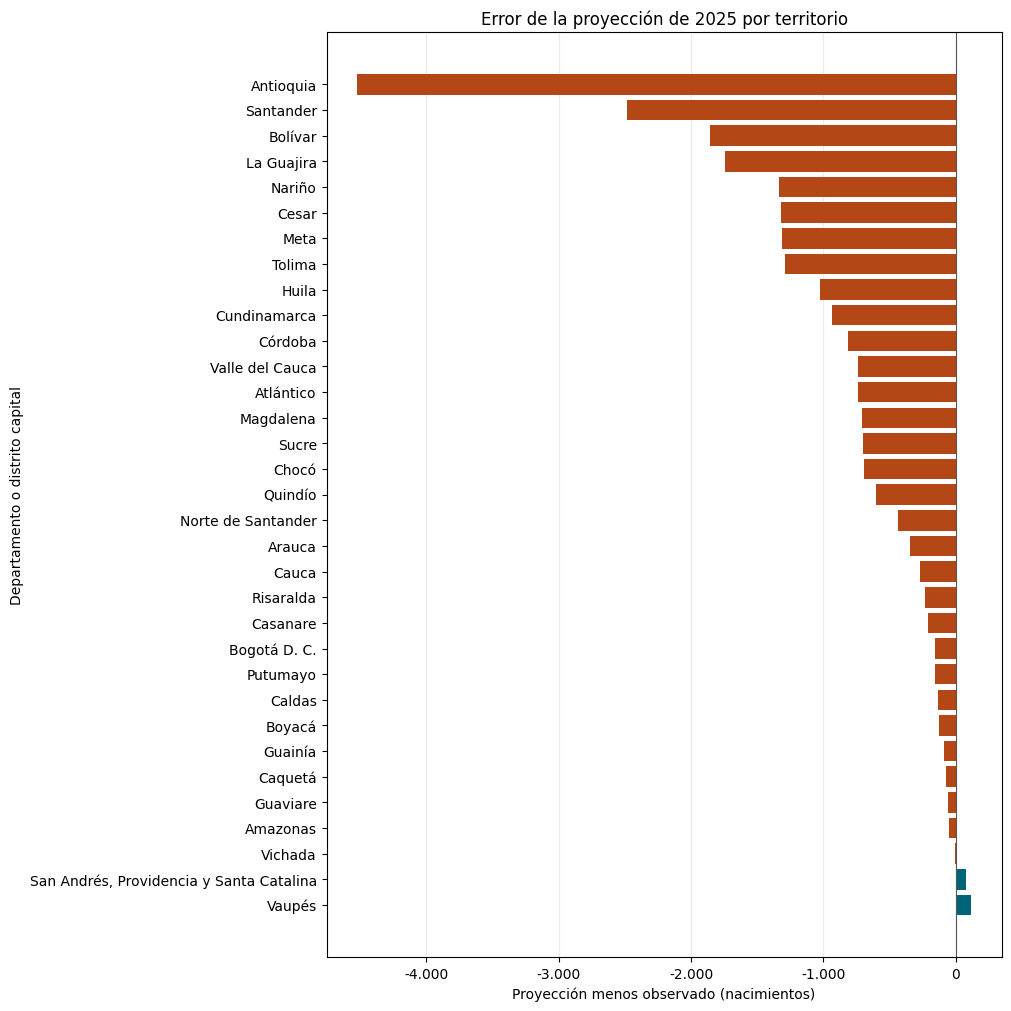

In [ ]:
diferencias = contraste.assign(
    Diferencia=contraste["Proyección 2025"] - contraste["Observado 2025"]
).sort_values("Diferencia")
fig, ax = plt.subplots(figsize=(10, 10), layout="constrained")
ax.barh(diferencias["Departamento"], diferencias["Diferencia"],
        color=np.where(diferencias["Diferencia"] < 0, "#b34716", "#006478"))
ax.axvline(0, color="#555555", linewidth=0.8)
ax.invert_yaxis()
ax.set(title="Error de la proyección de 2025 por territorio",
       xlabel="Proyección menos observado (nacimientos)",
       ylabel="Departamento o distrito capital")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: entero(v)))
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
plt.show()

## 6. Conclusiones

La prueba histórica mide el desempeño en una sola transición anual. Aunque cada corte tenga 33 territorios, el modelo aprende a partir de solo tres años objetivo antes de la prueba y cuatro para la proyección. Los territorios comparten cambios nacionales y las observaciones del mismo año no constituyen 33 pruebas temporales independientes. La selección basada en 2024 puede favorecer al método que mejor se adaptó a ese descenso específico. El contraste posterior de 2025 aporta una segunda transición.

El nivel de nacimientos, el departamento y el año no explican causalmente los cambios. Con más datos se podrían evaluar varias ventanas cronológicas e incorporar variables demográficas conocidas en la fecha de pronóstico. El ejercicio presenta estimaciones puntuales y carece de intervalos de predicción.

In [ ]:
ganador = metricas.iloc[0]
mae_base = metricas.loc[metricas["Método"].eq(referencia), "MAE"].iloc[0]
peor = detalle_2024.iloc[0]
delta_2024 = detalle_2024["Estimado"].sum() - detalle_2024["Observado"].sum()
if ganador["MAE"] < mae_base:
    comparacion_base = f"mejoró el MAE de persistencia en {decimal(mae_base - ganador['MAE'])} nacimientos por territorio"
else:
    comparacion_base = "igualó el MAE de persistencia"

display(Markdown(
    f"- **2024.** {elegido} obtuvo un MAE de **{decimal(ganador['MAE'])}** y un RMSE "
    f"de **{decimal(ganador['RMSE'])}** nacimientos por territorio, con R² de "
    f"**{decimal(ganador['R²'], 4)}**. En la prueba {comparacion_base}. "
    f"El mayor error absoluto fue de {decimal(peor['Error absoluto'])} en "
    f"{peor['Departamento']}. La diferencia agregada (estimado menos observado) fue "
    f"de {decimal(delta_2024)} nacimientos.\n"
    f"- **2025.** Se proyectaron **{entero(total_2025)}** nacimientos. El observado con la misma "
    f"cobertura fue de **{entero(control_2025['Suma territorial'])}**. La diferencia agregada "
    f"(proyección menos observado) fue de **{entero(brecha)}** nacimientos y el MAE territorial "
    f"fue de **{decimal(metricas_2025['MAE'])}**."
))

- **2024.** Random Forest obtuvo un MAE de **1.373,1** y un RMSE de **2.378,4** nacimientos por territorio, con R² de **0,9683**. En la prueba mejoró el MAE de persistencia en 601,2 nacimientos por territorio. El mayor error absoluto fue de 9.072,3 en Antioquia. La diferencia agregada (estimado menos observado) fue de 44.491,1 nacimientos.
- **2025.** Se proyectaron **406.913** nacimientos. El observado con la misma cobertura fue de **431.888**. La diferencia agregada (proyección menos observado) fue de **-24.975** nacimientos y el MAE territorial fue de **768,6**.